In [1]:
from run_dom_color import *
from album_store import *
from optimize import *
import matplotlib.pyplot as plt

/home/wkuki/spotiled/optimization/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
store = AlbumStore()
albums = load_albums(store)

In [3]:
print(albums[0])

LoadedAlbum(album=Album(id='1l8d3Ijl6gtfrcacgHdXHv', image_filename='Molesta-Skandal.jpg', color='#939A9AFF'), spotify_color=RGB(r=147, g=154, b=154), pixels=array([55036, 59164, 57215, ..., 61342, 61310, 59197],
      shape=(4096,), dtype=uint16))


In [4]:
# PARAMS = {'alpha': 1, 'beta': 74, 'gamma': 26}
# PARAMS = {'alpha': 1, 'beta': 0, 'gamma': 24}
# PARAMS = {'alpha': 1, 'beta': 66, 'gamma': 24}
PARAMS = {'alpha': 2, 'beta': 59, 'gamma': 25}

In [5]:
histograms = make_histograms(PARAMS)
evaluated = evaluate(albums, *histograms)
Y = np.sqrt(errors_of(evaluated))

In [6]:
H, X = np.histogram(Y, bins=20)

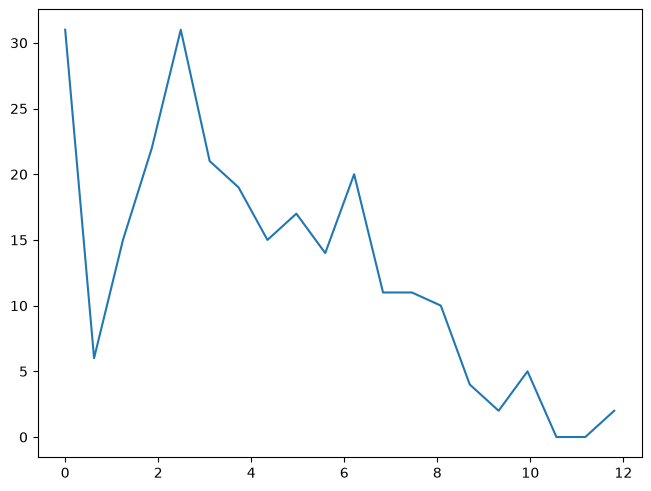

In [7]:
fig, ax = plt.subplots(1, layout='constrained')
ax.plot(X[:-1], H)

In [8]:
sorted_ix = np.argsort(Y)

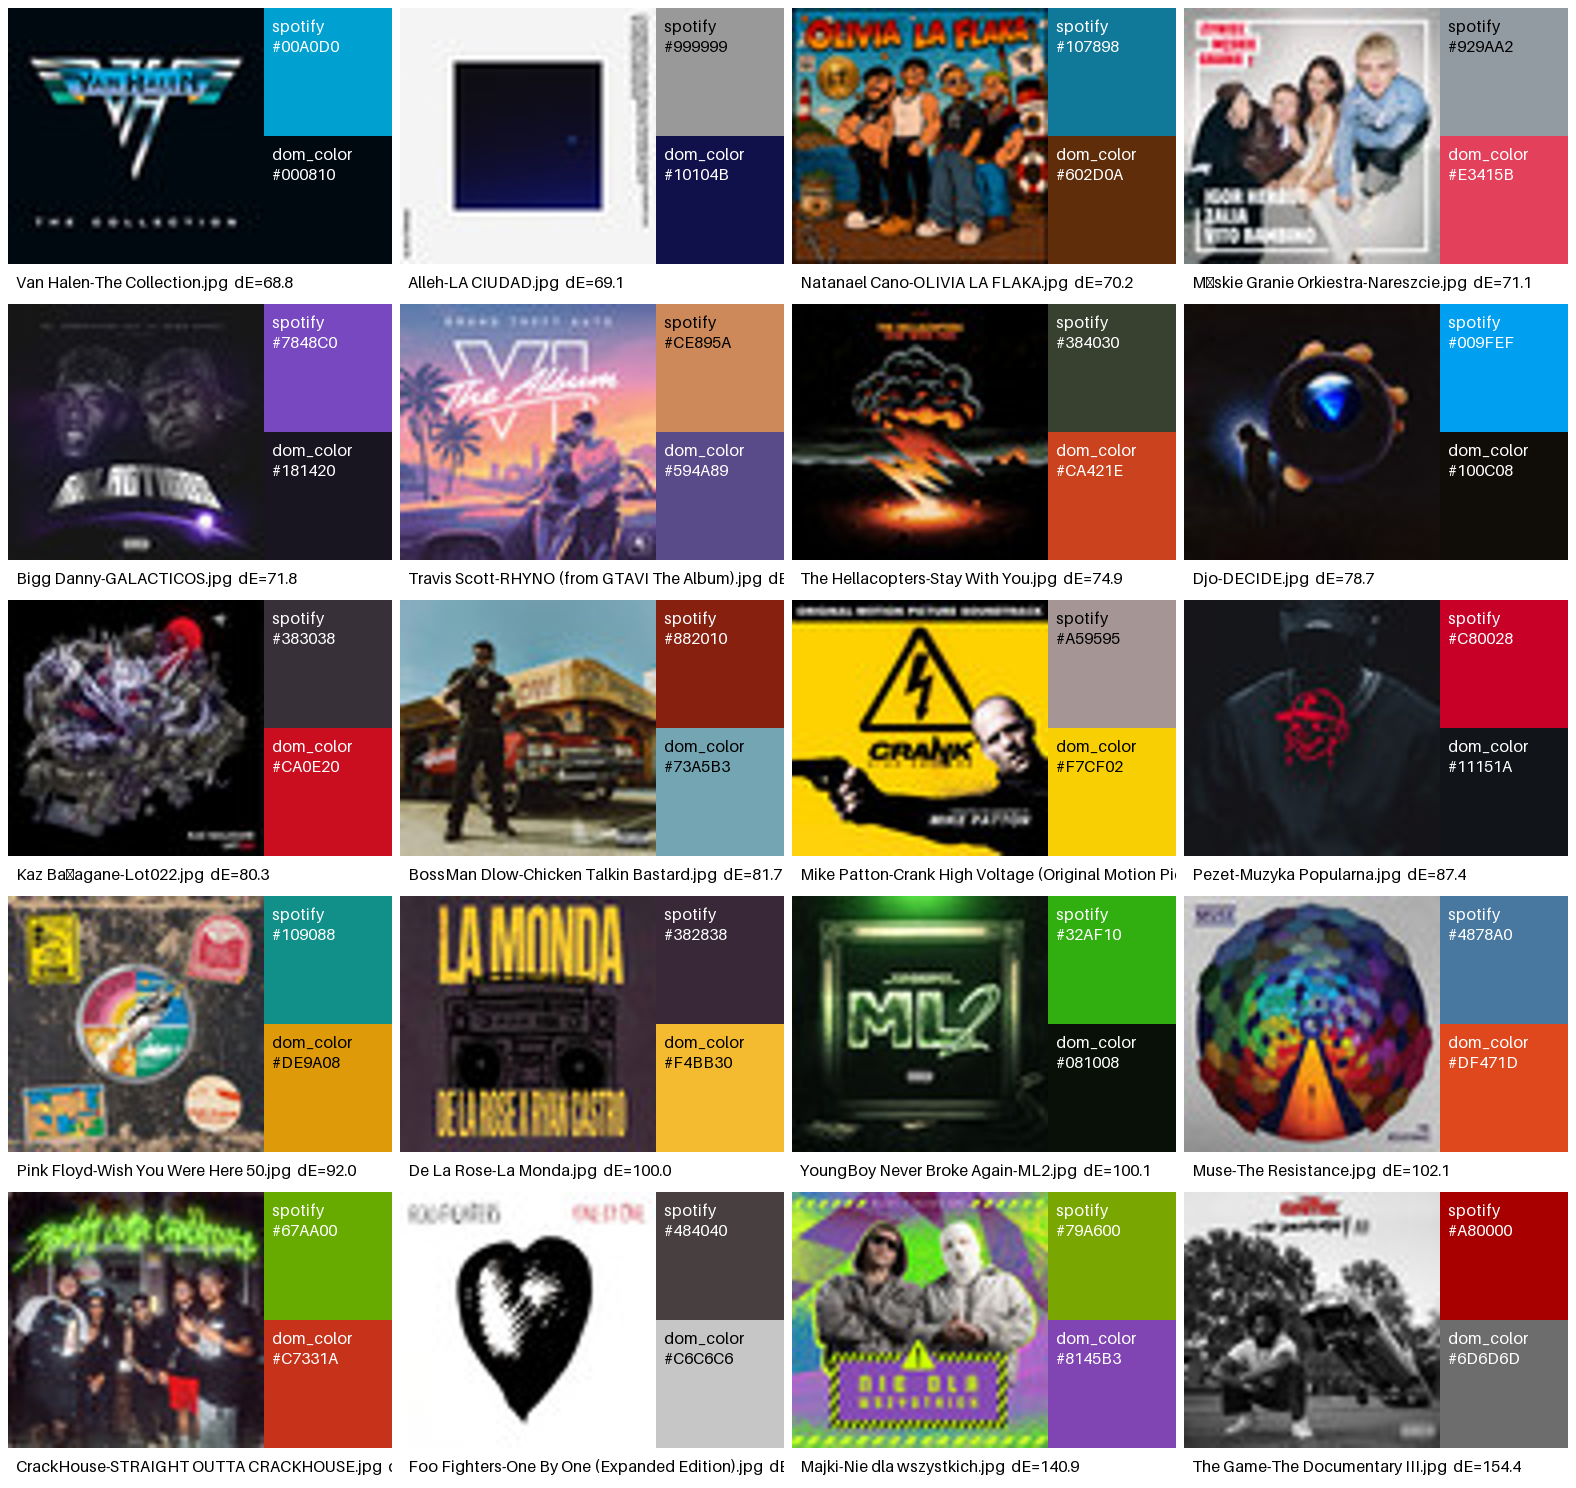

In [9]:
chosen_albums = [evaluated[ix] for ix in sorted_ix[-20:]]
make_collage(store, chosen_albums)

In [10]:
GRAY_SATURATION = 0.1  # HSV saturation below this counts as gray

def saturation(colors: list[RGB]) -> np.ndarray:
    rgb = metrics.rgb_to_array(colors)
    hi, lo = rgb.max(axis=1), rgb.min(axis=1)
    return np.divide(hi - lo, hi, out=np.zeros_like(hi), where=hi > 0)

spotify_gray = np.flatnonzero(saturation([e.loaded.spotify_color for e in evaluated]) < GRAY_SATURATION)
dom_color_gray = np.flatnonzero(saturation([e.predicted for e in evaluated]) < GRAY_SATURATION)
print(f"spotify gray: {len(spotify_gray)}, dom_color gray: {len(dom_color_gray)}")

spotify gray: 45, dom_color gray: 31


In [11]:
spotify_gray_albums = [evaluated[ix] for ix in spotify_gray]
dom_color_gray_albums = [evaluated[ix] for ix in dom_color_gray]

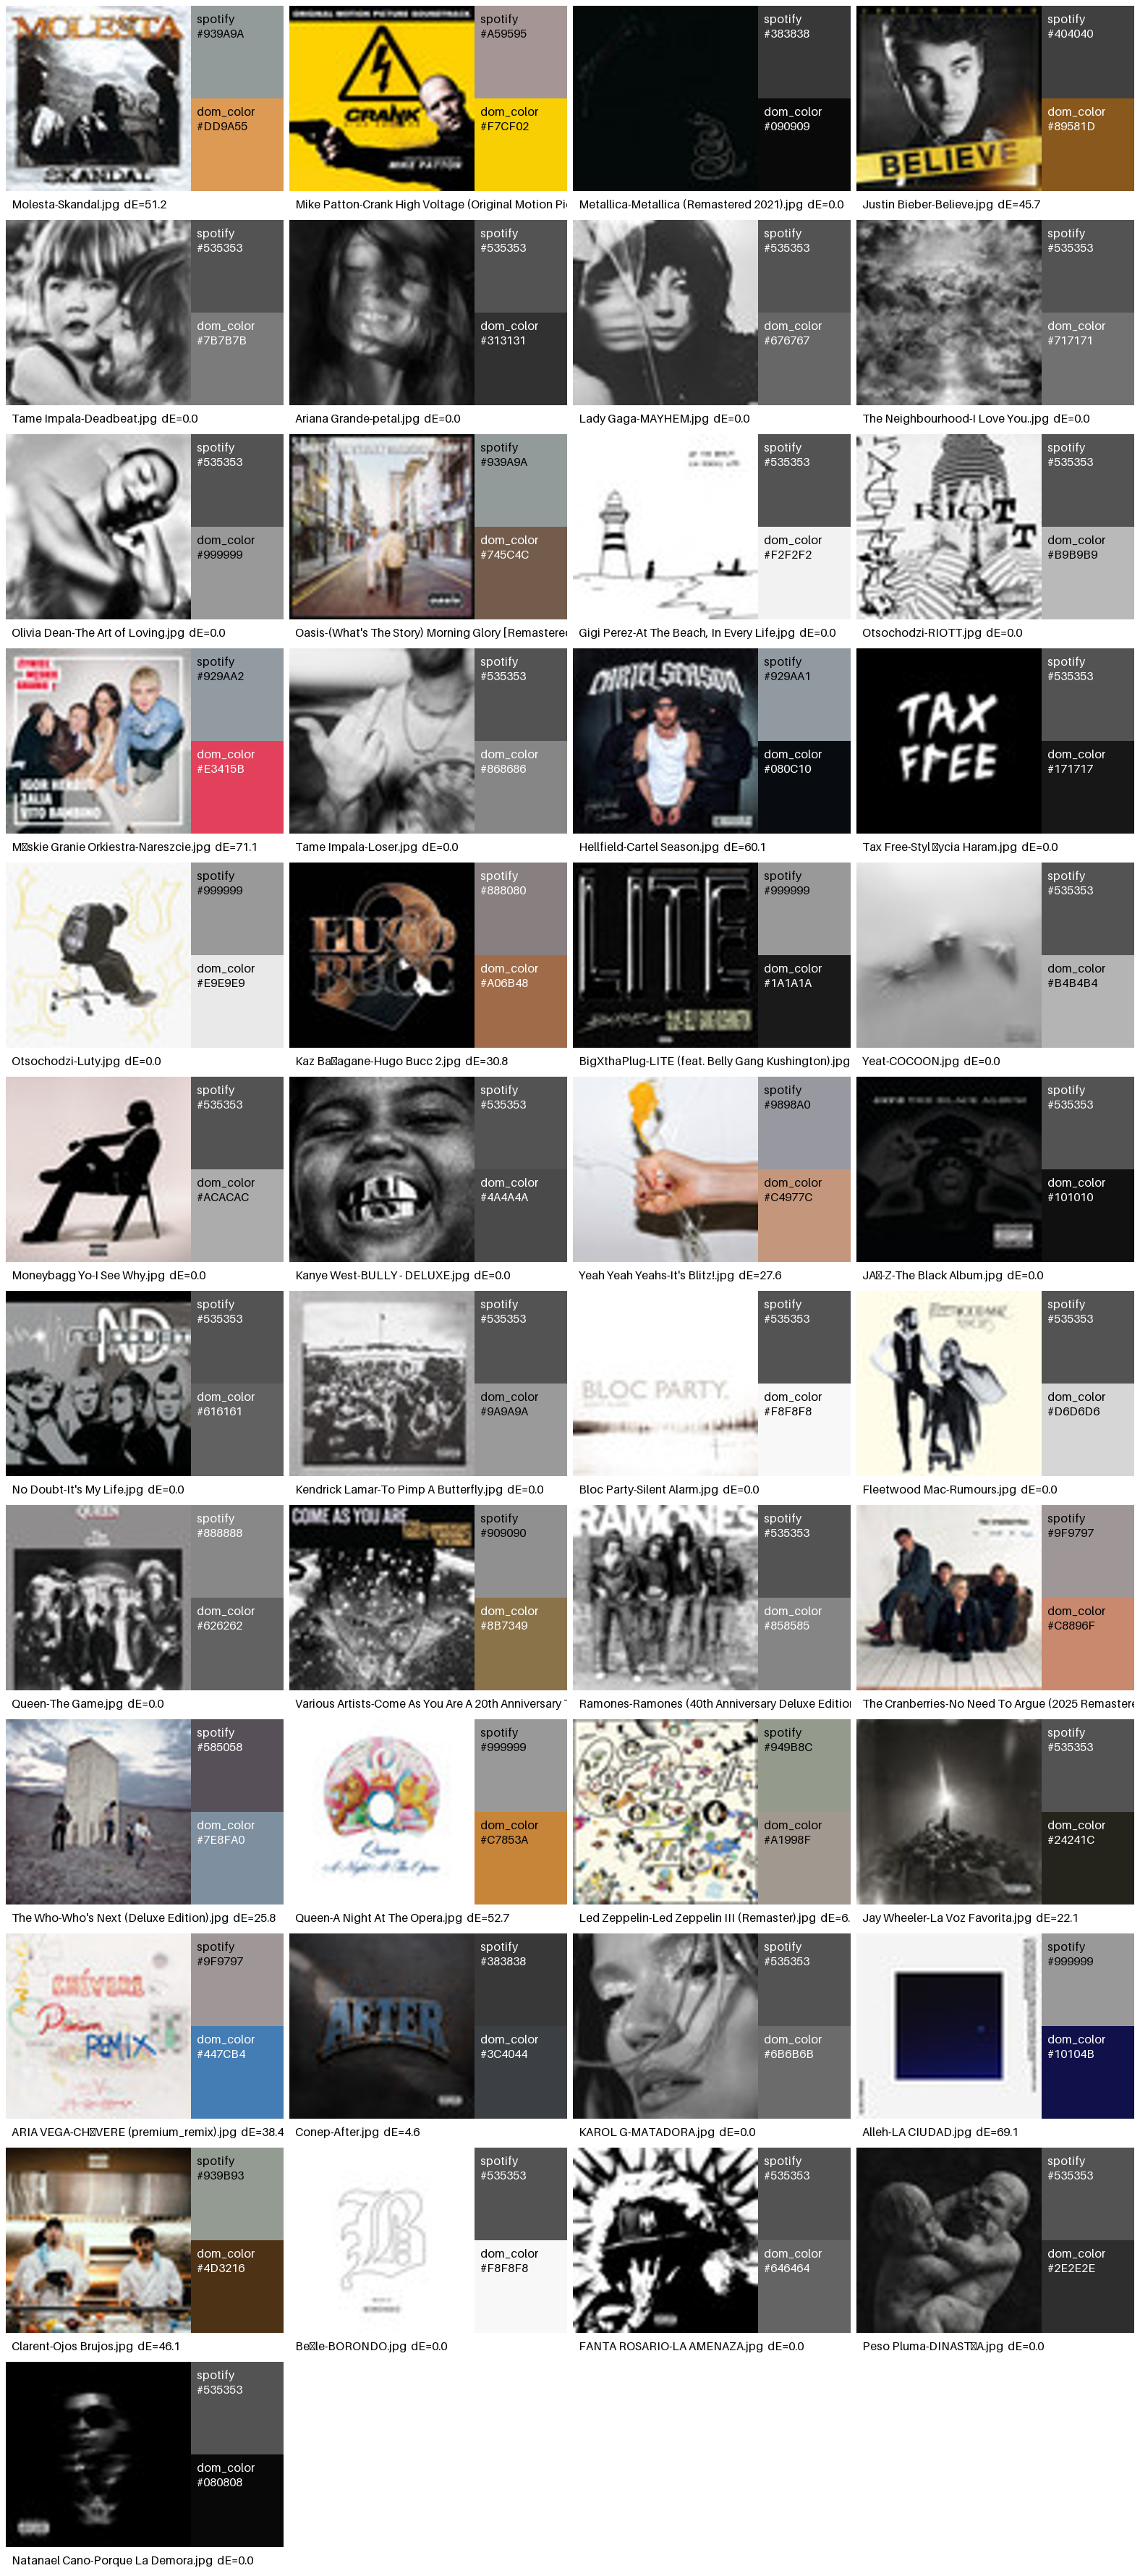

In [12]:
make_collage(store, spotify_gray_albums)

In [13]:
dom_color_gray

array([  6,  20,  24,  26,  27,  35,  41,  52,  66,  69,  76,  83,  87,
        93,  96, 101, 118, 140, 146, 149, 154, 163, 164, 165, 166, 169,
       233, 244, 248, 252, 255])